In [2]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

# Figure 3

In [ ]:
## Figure 3E

Load the data

In [6]:
annotations = pd.read_csv('../data/haoSub_annotations.csv', index_col=0)
genes = pd.read_csv('../data/haoSub_genes.csv', index_col=0)
counts = mmread('../data/haoSub_counts.mtx')
counts = pd.DataFrame(counts.todense())
counts = counts.T
counts.columns = genes['x']
adata_hao_sub = AnnData(counts, obs=annotations)

bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)

sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


For the standard Rectangle results we can take the results from figure 2

In [8]:
rectangle_fino_rmse, rectangle_fino_corr = 0.056, 0.906
rectangle_hoek_rmse, rectangle_hoek_corr = 0.071, 0.941
rectangle_chen_rmse, rectangle_chen_corr = 0.115, 0.836
rectangle_peti_rmse, rectangle_peti_corr = 0.144, 0.863

For the interventions we will create new results

First results without mRNA bias correction

In [ ]:
estimations_fino_no_bias, signature_results_fino_no_bias = rp.rectangle(adata_hao_sub, bulks_fino.T, correct_mrna_bias=False)
estimations_fino_no_bias.to_csv("../output/hao_estimations_fino_no_bias.csv")

hoek_estimations_no_bias, signature_results_hoek_no_bias = rp.rectangle(adata_hao_sub, bulks_hoek.T, correct_mrna_bias=False)
hoek_estimations_no_bias.to_csv("../output/hao_estimations_hoek_no_bias.csv")

chen_estimations_no_bias, signatures_chen_no_bias = rp.rectangle(adata_muris, bulks_chen.T, correct_mrna_bias=False)
chen_estimations_no_bias.to_csv("../output/muris_estimations_chen_no_bias.csv")

peti_estimations_no_bias, signatures_peti_no_bias = rp.rectangle(adata_muris, bulks_peti.T, correct_mrna_bias=False)
peti_estimations_no_bias.to_csv("../output/muris_estimations_peti_no_bias.csv")


In [12]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophils', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T

chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)
petitprez_gld = petitprez_gld.fillna(0)
petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

In [19]:
gld_m_f_skip_bias, finotello_m_skip_bias = helper.match_dfs(finotello_gld, estimations_fino_no_bias.T)
evaluation_fintotello_skip_bias = helper.create_evaluation_df(gld_m_skip_bias, finotello_m_skip_bias)
rsme_finotello_skip_bias, r_finotello_skip_bias, p_finotello_skip_bias = helper.evaulate_total_df(
    evaluation_fintotello_skip_bias)

In [25]:
hoek_estimations_no_bias = pd.read_csv("../output/hao_estimations_hoek_no_bias.csv", index_col=0)
hoek_estimations_no_bias['T cells'] = hoek_estimations_no_bias['T cells CD4 conv'] + hoek_estimations_no_bias['T cells CD8'] + hoek_estimations_no_bias[
    'Tregs']
gld_m_h_skip_bias, hoek_m_skip_bias = helper.match_dfs(hoek_gld, hoek_estimations_no_bias.T)

evaluation_hoek_skip_bias = helper.create_evaluation_df(gld_m_h_skip_bias, hoek_m_skip_bias)
rsme_hoek_skip_bias, r_hoek_skip_bias, p_hoek_skip_bias = helper.evaulate_total_df(
    evaluation_hoek_skip_bias)

In [27]:
chen_estimations_no_bias = pd.read_csv("../output/muris_estimations_chen_no_bias.csv", index_col=0)
chen_estimations_no_bias['T cells CD4 Total'] = chen_estimations_no_bias['T cells CD4 conv'] + chen_estimations_no_bias['Tregs']
gld_m_c_skip_bias, chen_m_skip_bias = helper.match_dfs(chen_gld, chen_estimations_no_bias)

evaluation_chen_skip_bias = helper.create_evaluation_df(gld_m_c_skip_bias, chen_m_skip_bias)
rsme_chen_skip_bias, r_chen_skip_bias, p_chen_skip_bias = helper.evaulate_total_df(
    evaluation_chen_skip_bias)


In [28]:
peti_estimations_no_bias = pd.read_csv("../output/muris_estimations_peti_no_bias.csv", index_col=0)
gld_m_p_skip_bias, petitprez_m_skip_bias = helper.match_dfs(petitprez_gld, peti_estimations_no_bias)


evaluation_petitprez_skip_bias = helper.create_evaluation_df(gld_m_p_skip_bias, petitprez_m_skip_bias)
rsme_petitprez_skip_bias, r_petitprez_skip_bias, p_petitprez_skip_bias = helper.evaulate_total_df(
    evaluation_petitprez_skip_bias)

Second, results without Grid search

In [ ]:
estimations_fino_no_grid, signature_results_fino_no_grid = rp.rectangle(adata_hao_sub, bulks_fino.T, optimize_cutoffs=False)
estimations_fino_no_grid.to_csv("../output/hao_estimations_fino_no_grid.csv")
hoek_estimations_no_grid, signature_results_hoek_no_grid = rp.rectangle(adata_hao_sub, bulks_hoek.T, optimize_cutoffs=False)
hoek_estimations_no_grid.to_csv("../output/hao_estimations_hoek_no_grid.csv")
chen_estimations_no_grid, signatures_chen_no_grid = rp.rectangle(adata_muris, bulks_chen.T, optimize_cutoffs=False)
chen_estimations_no_grid.to_csv("../output/muris_estimations_chen_no_grid.csv")
peti_estimations_no_grid, signatures_peti_no_grid = rp.rectangle(adata_muris, bulks_peti.T, optimize_cutoffs=False)
peti_estimations_no_grid.to_csv("../output/muris_estimations_peti_no_grid.csv")

In [31]:
gld_m_f_skip_grid, finotello_m_skip_grid = helper.match_dfs(finotello_gld, estimations_fino_no_grid.T)
evaluation_fintotello_skip_grid = helper.create_evaluation_df(gld_m_f_skip_grid, finotello_m_skip_grid)
rsme_finotello_skip_grid, r_finotello_skip_grid, p_finotello_skip_grid = helper.evaulate_total_df(
    evaluation_fintotello_skip_grid)


In [33]:
hoek_estimations_no_grid = pd.read_csv("../output/hao_estimations_hoek_no_grid.csv", index_col=0)
hoek_estimations_no_grid['T cells'] = hoek_estimations_no_grid['T cells CD4 conv'] + hoek_estimations_no_grid['T cells CD8'] + hoek_estimations_no_grid[
    'Tregs']
gld_m_h_skip_grid, hoek_m_skip_grid = helper.match_dfs(hoek_gld, hoek_estimations_no_grid.T)
evaluation_hoek_skip_grid = helper.create_evaluation_df(gld_m_h_skip_grid, hoek_m_skip_grid)
rsme_hoek_skip_grid, r_hoek_skip_grid, p_hoek_skip_grid = helper.evaulate_total_df(
    evaluation_hoek_skip_grid)


In [34]:
chen_estimations_no_grid = pd.read_csv("../output/muris_estimations_chen_no_grid.csv", index_col=0)
chen_estimations_no_grid['T cells CD4 Total'] = chen_estimations_no_grid['T cells CD4 conv'] + chen_estimations_no_grid['Tregs']
gld_m_c_skip_grid, chen_m_skip_grid = helper.match_dfs(chen_gld, chen_estimations_no_grid)
evaluation_chen_skip_grid = helper.create_evaluation_df(gld_m_c_skip_grid, chen_m_skip_grid)
rsme_chen_skip_grid, r_chen_skip_grid, p_chen_skip_grid = helper.evaulate_total_df(
    evaluation_chen_skip_grid)

In [35]:
peti_estimations_no_grid = pd.read_csv("../output/muris_estimations_peti_no_grid.csv", index_col=0)
gld_m_p_skip_grid, petitprez_m_skip_grid = helper.match_dfs(petitprez_gld, peti_estimations_no_grid)
evaluation_petitprez_skip_grid = helper.create_evaluation_df(gld_m_p_skip_grid, petitprez_m_skip_grid)
rsme_petitprez_skip_grid, r_petitprez_skip_grid, p_petitprez_skip_grid = helper.evaulate_total_df(
    evaluation_petitprez_skip_grid)


To see what the estimations look like without the unknown content correction, we can remove the unknown content from the estimations and normalize the results to 1

In [57]:
estimations_fino = pd.read_csv("../output/hao_estimations_fino_sub.csv", index_col=0)
estimations_finon_no_unknown = estimations_fino.drop('Unknown', axis=1)
estimations_finon_no_unknown = estimations_finon_no_unknown.div(estimations_finon_no_unknown.sum(axis=1), axis=0)
estimations_finon_no_unknown.to_csv("../output/hao_estimations_fino_no_unknown.csv")


In [56]:
estimations_hoek = pd.read_csv("../output/hao_estimations_hoek_sub.csv", index_col=0)
estimations_hoek_no_unknown = estimations_hoek.drop('Unknown', axis=1)
estimations_hoek_no_unknown = estimations_hoek_no_unknown.div(estimations_hoek_no_unknown.sum(axis=1), axis=0)
estimations_hoek_no_unknown.to_csv("../output/hao_estimations_hoek_no_unknown.csv")

In [60]:
estimations_chen = pd.read_csv("../output/muris_estimations_chen.csv", index_col=0)
estimations_chen_no_unknown = estimations_chen.drop('Unknown', axis=1)
estimations_chen_no_unknown = estimations_chen_no_unknown.div(estimations_chen_no_unknown.sum(axis=1), axis=0)
estimations_chen_no_unknown.to_csv("../output/muris_estimations_chen_no_unknown.csv")

In [65]:
estimations_peti = pd.read_csv("../output/muris_estimations_peti.csv", index_col=0)
estimations_peti_no_unknown = estimations_peti.drop('Unknown', axis=1)
estimations_peti_no_unknown = estimations_peti_no_unknown.div(estimations_peti_no_unknown.sum(axis=1), axis=0)
estimations_peti_no_unknown.to_csv("../output/muris_estimations_peti_no_unknown.csv")


In [54]:
gld_m_f_no_unknown, finotello_m_no_unknown = helper.match_dfs(finotello_gld, estimations_finon_no_unknown.T)
evaluation_fintotello_no_unknown = helper.create_evaluation_df(gld_m_f_no_unknown, finotello_m_no_unknown)
rsme_finotello_no_unknown, r_finotello_no_unknown, p_finotello_no_unknown = helper.evaulate_total_df(
    evaluation_fintotello_no_unknown)


In [61]:
hoek_estimations_no_unknown = pd.read_csv("../output/hao_estimations_hoek_no_unknown.csv", index_col=0)
hoek_estimations_no_unknown['T cells'] = hoek_estimations_no_unknown['T cells CD4 conv'] + hoek_estimations_no_unknown['T cells CD8'] + hoek_estimations_no_unknown[
    'Tregs']
gld_m_h_no_unknown, hoek_m_no_unknown = helper.match_dfs(hoek_gld, hoek_estimations_no_unknown.T)
evaluation_hoek_no_unknown = helper.create_evaluation_df(gld_m_h_no_unknown, hoek_m_no_unknown)
rsme_hoek_no_unknown, r_hoek_no_unknown, p_hoek_no_unknown = helper.evaulate_total_df(
    evaluation_hoek_no_unknown)


In [62]:
chen_estimations_no_unknown = pd.read_csv("../output/muris_estimations_chen_no_unknown.csv", index_col=0)
chen_estimations_no_unknown['T cells CD4 Total'] = chen_estimations_no_unknown['T cells CD4 conv'] + chen_estimations_no_unknown['Tregs']
gld_m_c_no_unknown, chen_m_no_unknown = helper.match_dfs(chen_gld, chen_estimations_no_unknown)
evaluation_chen_no_unknown = helper.create_evaluation_df(gld_m_c_no_unknown, chen_m_no_unknown)
rsme_chen_no_unknown, r_chen_no_unknown, p_chen_no_unknown = helper.evaulate_total_df(
    evaluation_chen_no_unknown)

In [66]:
peti_estimations_no_unknown = pd.read_csv("../output/muris_estimations_peti_no_unknown.csv", index_col=0)
gld_m_p_no_unknown, petitprez_m_no_unknown = helper.match_dfs(petitprez_gld, peti_estimations_no_unknown)
evaluation_petitprez_no_unknown = helper.create_evaluation_df(gld_m_p_no_unknown, petitprez_m_no_unknown)
rsme_petitprez_no_unknown, r_petitprez_no_unknown, p_petitprez_no_unknown = helper.evaulate_total_df(
    evaluation_petitprez_no_unknown)

Rectangle does not allow to skip the hierarchical deconvolution step, but we ca run the 2-step deconvolution and modify the clustered results so that hierachical deconvolution can not be applied.



In [ ]:
signature_result_fino = rp.pp.build_rectangle_signatures(adata_hao_sub,bulks=bulks_fino.T)
marker_genes_per_cell_type = signature_result_fino.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_fino.marker_genes_per_cell_type = marker_genes_per_cell_type

estimations_fino_no_hierarchy, _ = rp.tl.deconvolution(signature_result_fino,bulks_fino.T)
estimations_fino_no_hierarchy.to_csv("../output/hao_estimations_fino_no_hierarchy.csv")



In [ ]:
signature_result_hoek = rp.pp.build_rectangle_signatures(adata_hao_sub,bulks=bulks_hoek.T)
marker_genes_per_cell_type = signature_result_hoek.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_hoek.marker_genes_per_cell_type = marker_genes_per_cell_type
hoek_estimations_no_hierarchy, _ = rp.tl.deconvolution(signature_result_hoek,bulks_hoek.T)
hoek_estimations_no_hierarchy.to_csv("../output/hao_estimations_hoek_no_hierarchy.csv")

In [ ]:
signature_result_chen = rp.pp.build_rectangle_signatures(adata_muris,bulks=bulks_chen.T)
marker_genes_per_cell_type = signature_result_chen.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_chen.marker_genes_per_cell_type = marker_genes_per_cell_type
chen_estimations_no_hierarchy, _ = rp.tl.deconvolution(signature_result_chen,bulks=bulks_chen.T)
chen_estimations_no_hierarchy.to_csv("../output/muris_estimations_chen_no_hierarchy.csv")


In [ ]:
signature_result_peti = rp.pp.build_rectangle_signatures(adata_muris,bulks=bulks_peti.T)
marker_genes_per_cell_type = signature_result_peti.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_peti.marker_genes_per_cell_type = marker_genes_per_cell_type
peti_estimations_no_hierarchy, _ = rp.tl.deconvolution(signature_result_peti,bulks=bulks_peti.T)
peti_estimations_no_hierarchy.to_csv("../output/muris_estimations_peti_no_hierarchy.csv")

In [75]:
gld_m_f_no_hierarchy, finotello_m_no_hierarchy = helper.match_dfs(finotello_gld, estimations_fino_no_hierarchy.T)
evaluation_fintotello_no_hierarchy = helper.create_evaluation_df(gld_m_f_no_hierarchy, finotello_m_no_hierarchy)
rsme_finotello_no_hierarchy, r_finotello_no_hierarchy, p_finotello_no_hierarchy = helper.evaulate_total_df(
    evaluation_fintotello_no_hierarchy)


In [79]:
estimations_hoek_no_hierarchy = pd.read_csv("../output/hao_estimations_hoek_no_hierarchy.csv", index_col=0)
hoek_estimations_no_hierarchy['T cells'] = hoek_estimations_no_hierarchy['T cells CD4 conv'] + hoek_estimations_no_hierarchy['T cells CD8'] + hoek_estimations_no_hierarchy[
    'Tregs']
gld_m_h_no_hierarchy, hoek_m_no_hierarchy = helper.match_dfs(hoek_gld, hoek_estimations_no_hierarchy.T)
evaluation_hoek_no_hierarchy = helper.create_evaluation_df(gld_m_h_no_hierarchy, hoek_m_no_hierarchy)
rsme_hoek_no_hierarchy, r_hoek_no_hierarchy, p_hoek_no_hierarchy = helper.evaulate_total_df(
    evaluation_hoek_no_hierarchy)


In [80]:
estimations_chen_no_hierarchy = pd.read_csv("../output/muris_estimations_chen_no_hierarchy.csv", index_col=0)
chen_estimations_no_hierarchy['T cells CD4 Total'] = chen_estimations_no_hierarchy['T cells CD4 conv'] + chen_estimations_no_hierarchy['Tregs']
gld_m_c_no_hierarchy, chen_m_no_hierarchy = helper.match_dfs(chen_gld, chen_estimations_no_hierarchy)
evaluation_chen_no_hierarchy = helper.create_evaluation_df(gld_m_c_no_hierarchy, chen_m_no_hierarchy)
rsme_chen_no_hierarchy, r_chen_no_hierarchy, p_chen_no_hierarchy = helper.evaulate_total_df(
    evaluation_chen_no_hierarchy)

In [83]:
estimations_peti_no_hierarchy = pd.read_csv("../output/muris_estimations_peti_no_hierarchy.csv", index_col=0)
gld_m_p_no_hierarchy, petitprez_m_no_hierarchy = helper.match_dfs(petitprez_gld, peti_estimations_no_hierarchy)
evaluation_petitprez_no_hierarchy = helper.create_evaluation_df(gld_m_p_no_hierarchy, petitprez_m_no_hierarchy)
rsme_petitprez_no_hierarchy, r_petitprez_no_hierarchy, p_petitprez_no_hierarchy = helper.evaulate_total_df(
    evaluation_petitprez_no_hierarchy)

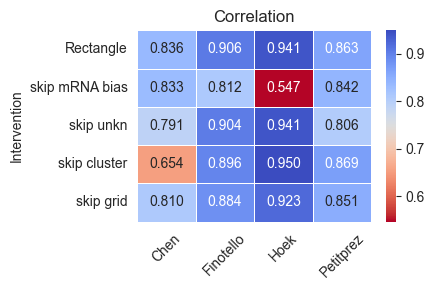

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
sns.set_style("white")

# Values and categories
values = [rectangle_hoek_corr, r_hoek_skip_bias, r_hoek_no_unknown, r_hoek_no_hierarchy, r_hoek_skip_grid]
interventions = ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


# Create DataFrame
df = pd.DataFrame({'Intervention': interventions, 'Delta': values})
df['Set'] = 'hoek'

values_f = [rectangle_fino_corr,  r_finotello_skip_bias, r_finotello_no_unknown, r_finotello_no_hierarchy, r_finotello_skip_grid]
interventions_f =  ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_f = pd.DataFrame({'Intervention': interventions_f, 'Delta': values_f})
df_f['Set'] = 'finotello'

values_c = [rectangle_chen_corr, r_chen_skip_bias, r_chen_no_unknown, r_chen_no_hierarchy, r_chen_skip_grid]
interventions_c = ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_c = pd.DataFrame({'Intervention': interventions_c, 'Delta': values_c})
df_c['Set'] = 'chen'

values_p = [rectangle_peti_corr, r_petitprez_skip_bias, r_petitprez_no_unknown, r_petitprez_no_hierarchy, r_petitprez_skip_grid]
interventions_p = ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_p = pd.DataFrame({'Intervention': interventions_p, 'Delta': values_p})
df_p['Set'] = 'petitprez'

df_corr_int  =  df_c['Delta'].to_frame()
df_corr_int['Chen'] = df_c['Delta']
df_corr_int['Finotello'] = df_f['Delta']
df_corr_int['Hoek'] = df['Delta']
df_corr_int['Petitprez'] = df_p['Delta']

df_corr_int['Intervention'] = df['Intervention']
df_corr_int = df_corr_int.drop('Delta', axis=1)


plt.figure(figsize=(4.5, 3))
sns.heatmap(df_corr_int.set_index('Intervention'), annot=True, cmap='coolwarm_r', fmt=".3f", linewidths=.5)
plt.title("Correlation")
# 90 degree rotation of x-axis labels
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../figures/fig3c3e_corr_int_heatmap.pdf')



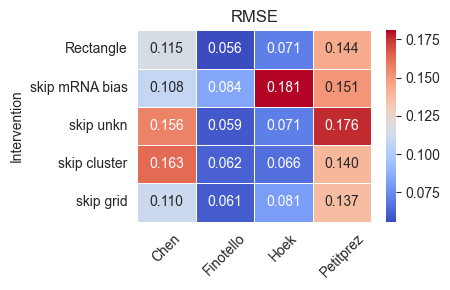

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_style("white")

palette = sns.color_palette('deep')[:4]
first_three_hex_colors = ['#%02x%02x%02x' % (int(color[0]*255), int(color[1]*255), int(color[2]*255)) for color in palette]

# Values and categories
values = [rectangle_hoek_rmse, rsme_hoek_skip_bias, rsme_hoek_no_unknown, rsme_hoek_no_hierarchy, rsme_hoek_skip_grid]
interventions =  ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


# Create DataFrame
df = pd.DataFrame({'Intervention': interventions, 'Delta': values})
df['Set'] = 'hoek'

values_f = [rectangle_fino_rmse, rsme_finotello_skip_bias, rsme_finotello_no_unknown, rsme_finotello_no_hierarchy, rsme_finotello_skip_grid]
interventions_f =  ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_f = pd.DataFrame({'Intervention': interventions_f, 'Delta': values_f})
df_f['Set'] = 'finotello'

values_c = [rectangle_chen_rmse, rsme_chen_skip_bias, rsme_chen_no_unknown, rsme_chen_no_hierarchy, rsme_chen_skip_grid]
interventions_c = ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_c = pd.DataFrame({'Intervention': interventions_c, 'Delta': values_c})
df_c['Set'] = 'chen'

values_p = [rectangle_peti_rmse, rsme_petitprez_skip_bias, rsme_petitprez_no_unknown, rsme_petitprez_no_hierarchy, rsme_petitprez_skip_grid]
interventions_p = ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_p = pd.DataFrame({'Intervention': interventions_p, 'Delta': values_p})
df_p['Set'] = 'petitprez'

df_rsme_int  =  df_c['Delta'].to_frame()
df_rsme_int['Chen'] = df_c['Delta']
df_rsme_int['Finotello'] = df_f['Delta']
df_rsme_int['Hoek'] = df['Delta']
df_rsme_int['Petitprez'] = df_p['Delta']

df_rsme_int['Intervention'] = df['Intervention']
df_rsme_int = df_rsme_int.drop('Delta', axis=1)


plt.figure(figsize=(4.5, 3))
sns.heatmap(df_rsme_int.set_index('Intervention'), annot=True, cmap='coolwarm', fmt=".3f", linewidths=.5)
plt.title("RMSE")
# 90 degree rotation of x-axis labels
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../figures/fig3c3e_rmse_int_heatmap.pdf')




